In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import random

Data Mining

In [ ]:
df_raw = pd.read_csv("Breast_Cancer.csv")
df_raw.head(5)

,Age,Race,Marital Status,T Stage,N Stage,6th Stage,differentiate,Grade,A Stage,Tumor Size,Estrogen Status,Progesterone Status,Regional Node Examined,Reginol Node Positive,Survival Months,Status
0,68,White,Married,T1,N1,IIA,Poorly differentiated,3,Regional,4,Positive,Positive,24,1,60,Alive
1,50,White,Married,T2,N2,IIIA,Moderately differentiated,2,Regional,35,Positive,Positive,14,5,62,Alive
2,58,White,Divorced,T3,N3,IIIC,Moderately differentiated,2,Regional,63,Positive,Positive,14,7,75,Alive
3,58,White,Married,T1,N1,IIA,Poorly differentiated,3,Regional,18,Positive,Positive,2,1,84,Alive
4,47,White,Married,T2,N1,IIB,Poorly differentiated,3,Regional,41,Positive,Positive,3,1,50,Alive


In [ ]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4024 entries, 0 to 4023
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   Age                     4024 non-null   int64 
 1   Race                    4024 non-null   object
 2   Marital Status          4024 non-null   object
 3   T Stage                 4024 non-null   object
 4   N Stage                 4024 non-null   object
 5   6th Stage               4024 non-null   object
 6   differentiate           4024 non-null   object
 7   Grade                   4024 non-null   object
 8   A Stage                 4024 non-null   object
 9   Tumor Size              4024 non-null   int64 
 10  Estrogen Status         4024 non-null   object
 11  Progesterone Status     4024 non-null   object
 12  Regional Node Examined  4024 non-null   int64 
 13  Reginol Node Positive   4024 non-null   int64 
 14  Survival Months         4024 non-null   int64 
 15  Stat

In [ ]:
df_raw.isnull().sum()


,0
Age,0
Race,0
Marital Status,0
T Stage,0
N Stage,0
6th Stage,0
differentiate,0
Grade,0
A Stage,0
Tumor Size,0


In [ ]:
df_raw['Status'].value_counts()

,count
Status,
Alive,3408
Dead,616


Data Exploration

<ipython-input-17-ea466e46e2c4>:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x = "Status", data = df_raw, palette = ["limegreen", "cyan"])


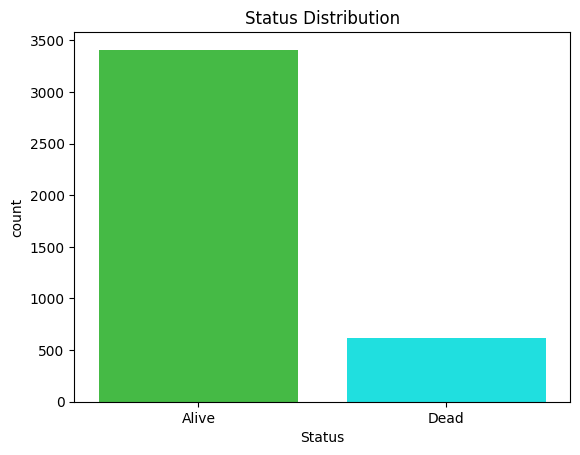

In [ ]:
sns.countplot(x = "Status", data = df_raw, palette = ["limegreen", "cyan"])
plt.title(label = "Status Distribution")
plt.show()

<ipython-input-18-6c1451b6980b>:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x = "Race", data = df_raw, palette = ["yellow", "red", "blue"])


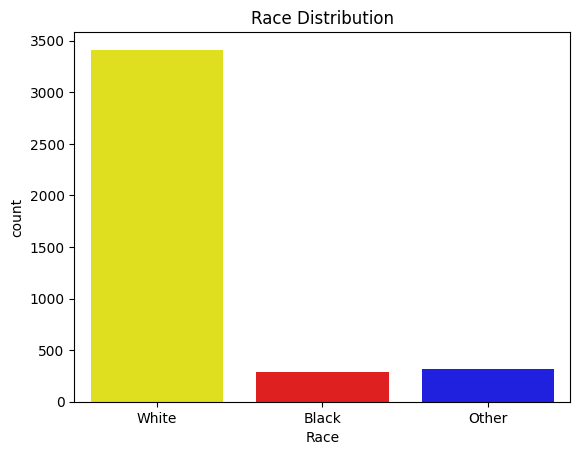

In [ ]:
sns.countplot(x = "Race", data = df_raw, palette = ["yellow", "red", "blue"])
plt.title(label = "Race Distribution")
plt.show()

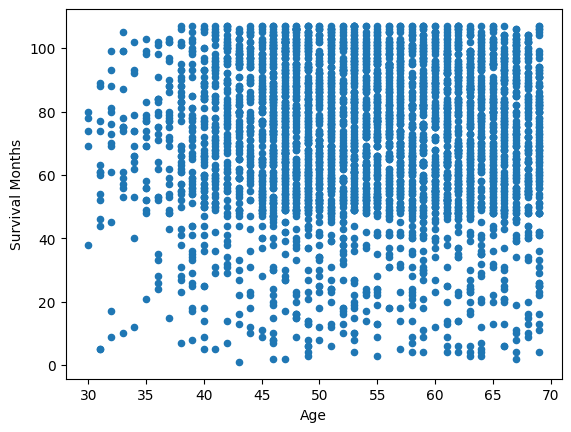

In [ ]:
df_raw.plot.scatter(x = "Age", y = "Survival Months")
plt.show()

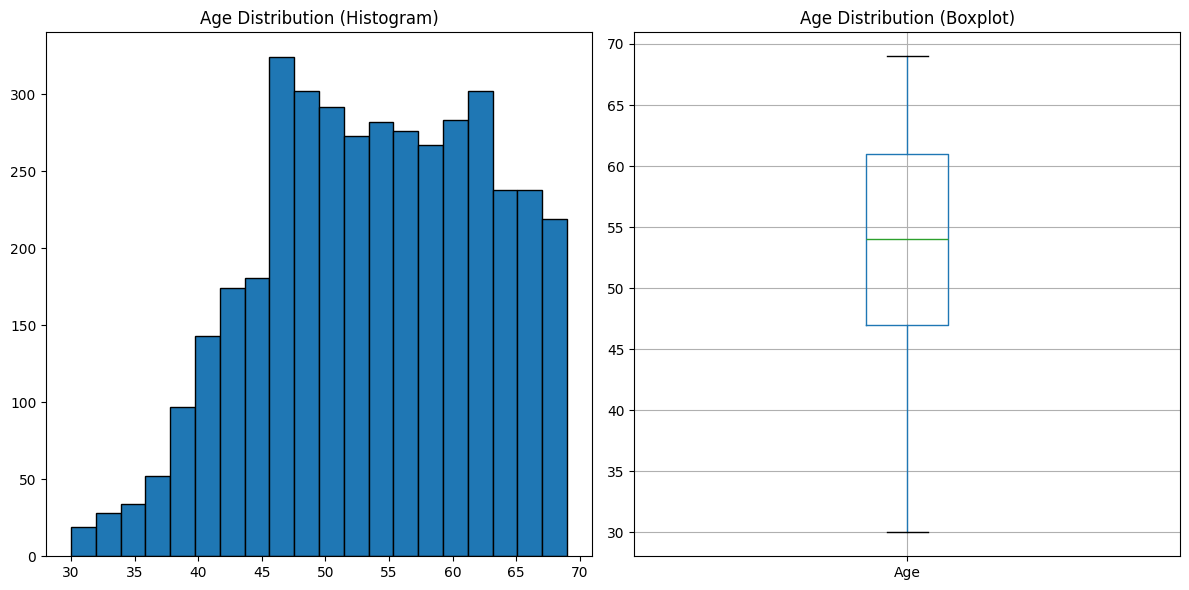

In [ ]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 6))

axes[0].hist(df_raw['Age'], bins=20, edgecolor='black')
axes[0].set_title("Age Distribution (Histogram)")

df_raw[['Age']].boxplot(ax=axes[1])
axes[1].set_title("Age Distribution (Boxplot)")

plt.tight_layout()
plt.show()

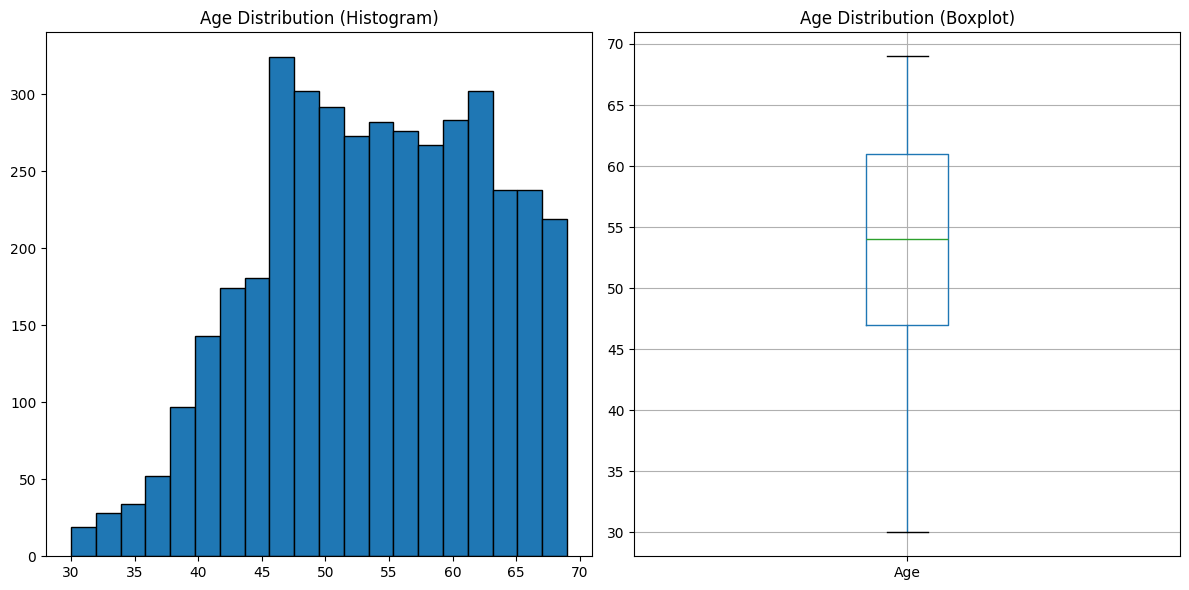

In [ ]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 6))

axes[0].hist(df_raw['Age'], bins=20, edgecolor='black')
axes[0].set_title("Age Distribution (Histogram)")

df_raw[['Age']].boxplot(ax=axes[1])
axes[1].set_title("Age Distribution (Boxplot)")

plt.tight_layout()
plt.show()

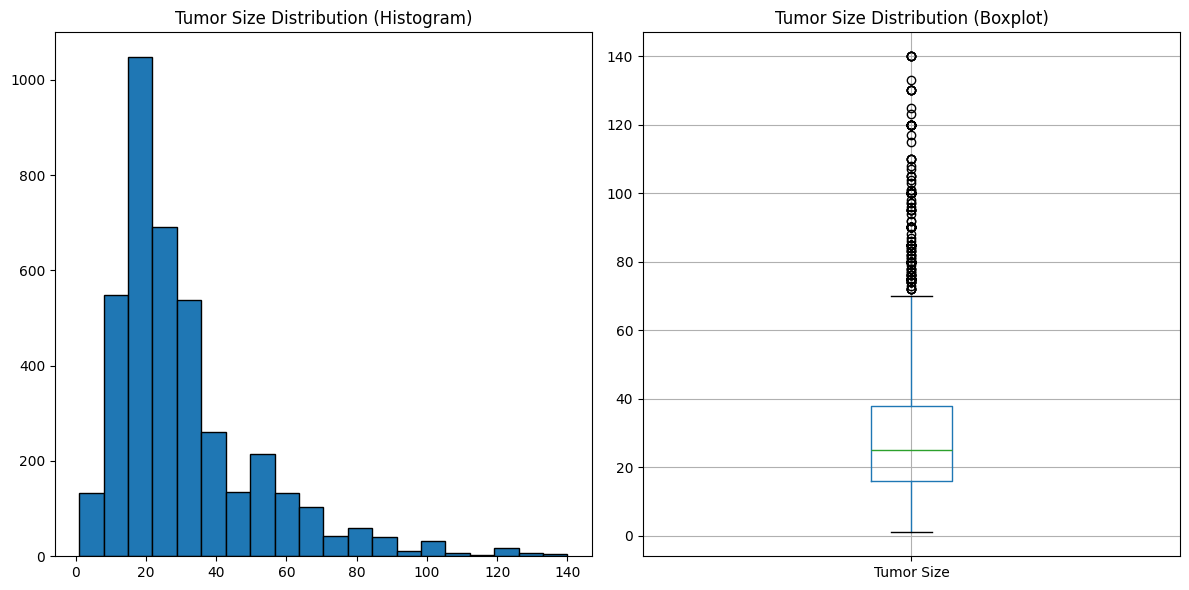

In [ ]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 6))

axes[0].hist(df_raw['Tumor Size'], bins=20, edgecolor='black')
axes[0].set_title("Tumor Size Distribution (Histogram)")

df_raw[['Tumor Size']].boxplot(ax=axes[1])
axes[1].set_title("Tumor Size Distribution (Boxplot)")

plt.tight_layout()
plt.show()

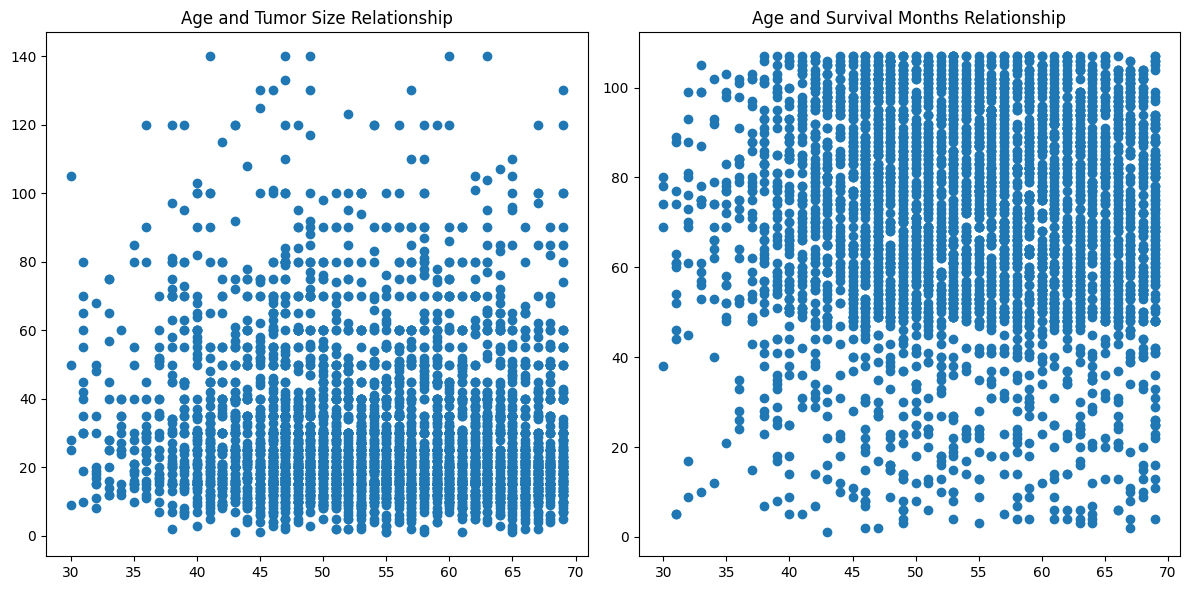

In [ ]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 6))

axes[0].scatter(x = df_raw["Age"], y = df_raw["Tumor Size"])
axes[0].set_title("Age and Tumor Size Relationship")

axes[1].scatter(x = df_raw["Age"], y = df_raw["Survival Months"])
axes[1].set_title("Age and Survival Months Relationship")

plt.tight_layout()
plt.show()

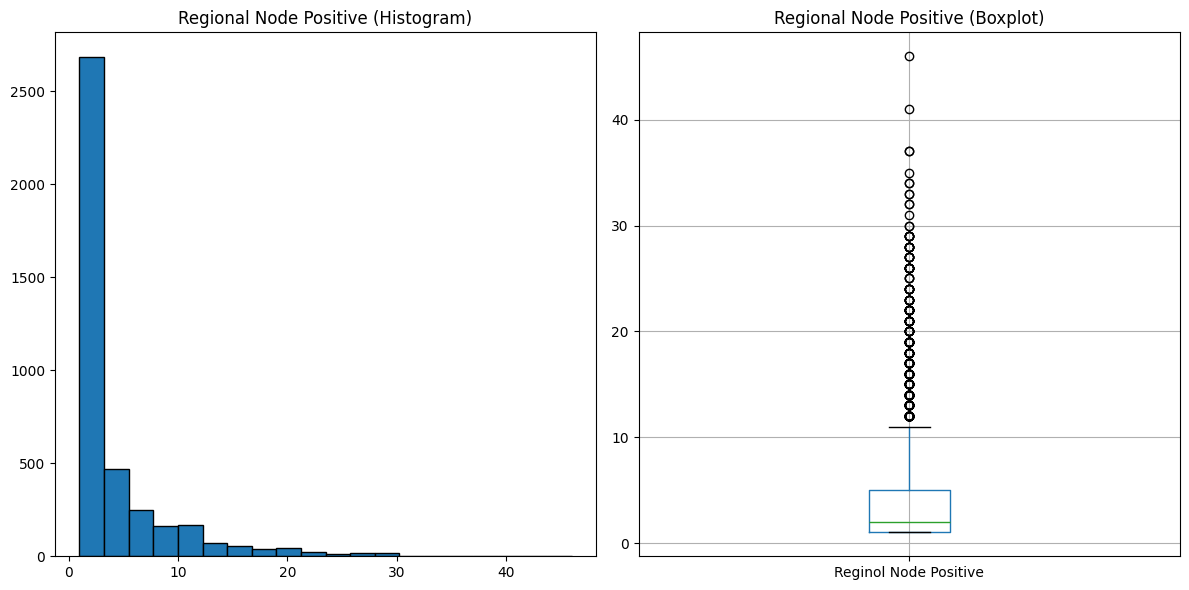

In [ ]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 6))

axes[0].hist(df_raw['Reginol Node Positive'], bins=20, edgecolor='black')
axes[0].set_title("Regional Node Positive (Histogram)")

df_raw[['Reginol Node Positive']].boxplot(ax=axes[1])
axes[1].set_title("Regional Node Positive (Boxplot)")

plt.tight_layout()
plt.show()

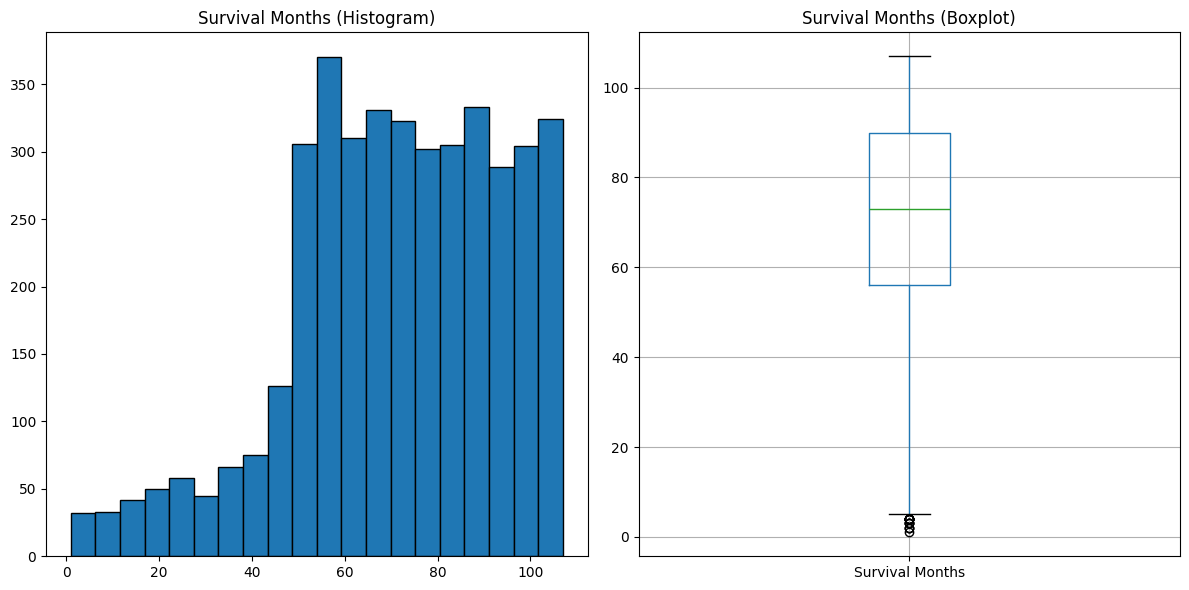

In [ ]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 6))

axes[0].hist(df_raw['Survival Months'], bins=20, edgecolor='black')
axes[0].set_title("Survival Months (Histogram)")

df_raw[['Survival Months']].boxplot(ax=axes[1])
axes[1].set_title("Survival Months (Boxplot)")

plt.tight_layout()
plt.show()

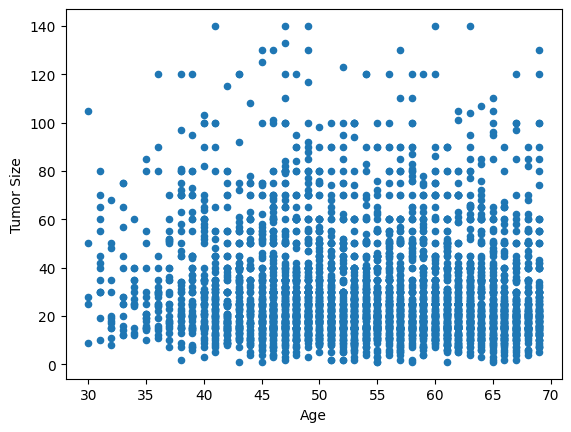

In [ ]:
df_raw.plot.scatter(x = "Age", y = "Tumor Size")
plt.show()

<Axes: title={'center': 'Age'}, xlabel='[Status]'>

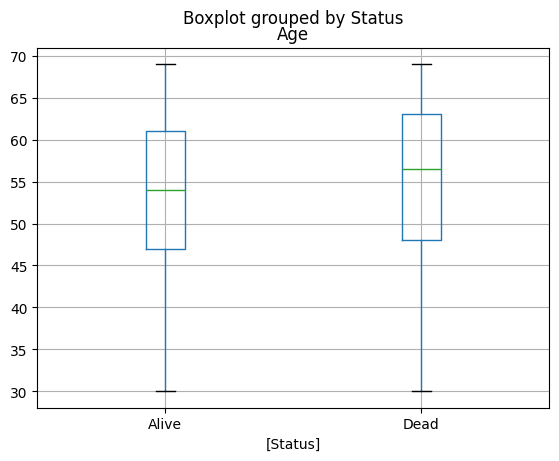

In [ ]:
df_raw[['Status', 'Age']].boxplot(by = "Status")

<Axes: >

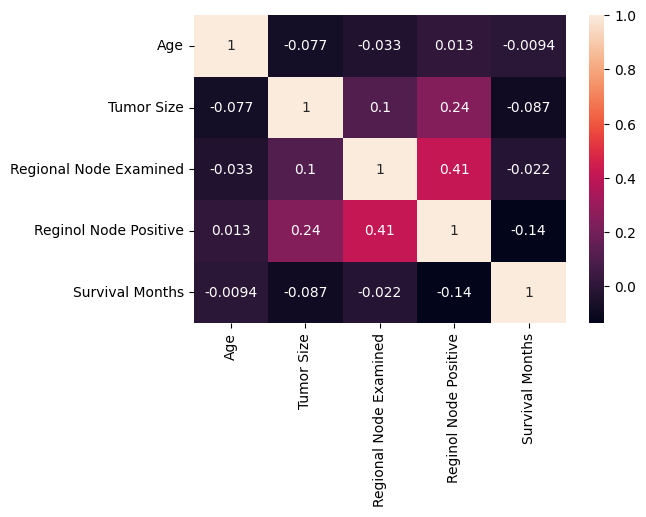

In [ ]:
# Correlation Analysis

df_temp = df_raw.drop(['Status', 'Race', 'Marital Status', 'T Stage ', 'Grade', 'N Stage', '6th Stage', 'differentiate', 'A Stage', 'Progesterone Status',
                       'Estrogen Status'], axis = 1)
df_temp.corr()
plt.figure(figsize = (6,4))
sns.heatmap(df_temp.corr(), annot = True)

In [ ]:
import scipy.stats as stats

cat_cols = df_raw.select_dtypes(include='object').columns.tolist()

cat_cols = [col for col in cat_cols if col != 'Status']

results = []

for col in cat_cols:
    contingency = pd.crosstab(df_raw[col], df_raw['Status'])
    chi2, p, dof, expected = stats.chi2_contingency(contingency)
    results.append({
        'Variable': col,
        'Chi2': chi2,
        'p-value': p,
        'Significant': 'Yes' if p < 0.05 else 'No'
    })

chi2_results = pd.DataFrame(results)
print(chi2_results)

              Variable        Chi2       p-value Significant
0                 Race   27.970007  8.440929e-07         Yes
1       Marital Status   28.263813  1.102769e-05         Yes
2             T Stage   103.476309  2.779095e-22         Yes
3              N Stage  269.929143  2.430141e-59         Yes
4            6th Stage  281.648443  9.830332e-60         Yes
5        differentiate  112.556276  3.091352e-24         Yes
6                Grade  112.556276  3.091352e-24         Yes
7              A Stage   35.764727  2.226426e-09         Yes
8      Estrogen Status  135.155739  3.052608e-31         Yes
9  Progesterone Status  124.885388  5.392080e-29         Yes


In [ ]:
# T-Test for Numerical Variables
from scipy.stats import ttest_ind

status_categories = df_raw['Status'].unique()
if len(status_categories) == 2:
    group1 = df_raw[df_raw['Status'] == status_categories[0]]
    group2 = df_raw[df_raw['Status'] == status_categories[1]]

    results = []
    for col in df_temp:
        tstat, pval = ttest_ind(group1[col].dropna(), group2[col].dropna(), equal_var=False)
        results.append({
            'Variable': col,
            'T-statistic': round(tstat, 4),
            'p-value': pval,
            'Significant': 'Yes' if pval < 0.05 else 'No'
        })

    ttest_results = pd.DataFrame(results)
    print(ttest_results)

                 Variable  T-statistic        p-value Significant
0                     Age      -3.3229   9.309078e-04         Yes
1              Tumor Size      -7.6265   7.019568e-14         Yes
2  Regional Node Examined      -2.1223   3.411297e-02         Yes
3   Reginol Node Positive     -11.9771   3.440363e-30         Yes
4         Survival Months      29.7029  1.192571e-129         Yes


Feature Engineering

In [ ]:
df_engineering = df_raw.copy()

df_engineering['Progesterone Status'] = df_engineering['Progesterone Status'].replace({'Positive': 'Pos', 'Negative': 'Neg'})
df_engineering.head()

,Age,Race,Marital Status,T Stage,N Stage,6th Stage,differentiate,Grade,A Stage,Tumor Size,Estrogen Status,Progesterone Status,Regional Node Examined,Reginol Node Positive,Survival Months,Status
0,68,White,Married,T1,N1,IIA,Poorly differentiated,3,Regional,4,Positive,Pos,24,1,60,Alive
1,50,White,Married,T2,N2,IIIA,Moderately differentiated,2,Regional,35,Positive,Pos,14,5,62,Alive
2,58,White,Divorced,T3,N3,IIIC,Moderately differentiated,2,Regional,63,Positive,Pos,14,7,75,Alive
3,58,White,Married,T1,N1,IIA,Poorly differentiated,3,Regional,18,Positive,Pos,2,1,84,Alive
4,47,White,Married,T2,N1,IIB,Poorly differentiated,3,Regional,41,Positive,Pos,3,1,50,Alive


In [ ]:
from sklearn.preprocessing import OneHotEncoder

In [ ]:
df_engineering['Grade'].unique()

array(['3', '2', '1', ' anaplastic; Grade IV'], dtype=object)

In [ ]:
# One Hot Encoder
from sklearn.preprocessing import OneHotEncoder

cat_encoder = OneHotEncoder(handle_unknown='ignore', sparse_output = False).set_output(transform = 'pandas')
df_transform = cat_encoder.fit_transform(df_engineering[['Race', 'Marital Status', 'A Stage', 'Estrogen Status', 'Progesterone Status']])

df_transform

,Race_Black,Race_Other,Race_White,Marital Status_Divorced,Marital Status_Married,Marital Status_Separated,Marital Status_Single,Marital Status_Widowed,A Stage_Distant,A Stage_Regional,Estrogen Status_Negative,Estrogen Status_Positive,Progesterone Status_Neg,Progesterone Status_Pos
0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0
1,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0
2,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0
3,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0
4,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4019,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0
4020,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0
4021,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0
4022,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0


In [ ]:
# Ordinal Encoding

df_engineering ['T Stage '] = df_engineering ['T Stage '].map({'T1': 1, 'T2': 2, 'T3': 3, 'T4': 4})
df_engineering ['N Stage'] = df_engineering ['N Stage'].map({'N1': 1, 'N2': 2, 'N3': 3})
df_engineering ['differentiate'] = df_engineering ['differentiate'].map({'Undifferentiated': 4, 'Poorly differentiated': 3, 'Moderately differentiated': 2, 'Well differentiated': 1})
df_engineering['6th Stage'] = df_engineering['6th Stage'].map({'IIA': 1, 'IIB': 2, 'IIIA': 3, 'IIIB': 4, 'IIIC': 5})
df_engineering['Grade'] = df_engineering['Grade'].map({'1': 1, '2': 2, '3': 3, ' anaplastic; Grade IV': 4})

In [ ]:
df_transform = pd.concat([df_engineering, df_transform], axis = 1).drop(columns = ['Race', 'Marital Status', 'A Stage',
                                                                           'Estrogen Status', 'Progesterone Status'])
df_transform.columns

Index(['Age', 'T Stage ', 'N Stage', '6th Stage', 'differentiate', 'Grade',
       'Tumor Size', 'Regional Node Examined', 'Reginol Node Positive',
       'Survival Months', 'Status', 'Race_Black', 'Race_Other', 'Race_White',
       'Marital Status_Divorced', 'Marital Status_Married',
       'Marital Status_Separated', 'Marital Status_Single ',
       'Marital Status_Widowed', 'A Stage_Distant', 'A Stage_Regional',
       'Estrogen Status_Negative', 'Estrogen Status_Positive',
       'Progesterone Status_Neg', 'Progesterone Status_Pos'],
      dtype='object')

In [ ]:
print(len(df_transform))
print(len(df_raw))

4024
4024


In [ ]:
df_transform.head()

,Age,T Stage,N Stage,6th Stage,differentiate,Grade,Tumor Size,Regional Node Examined,Reginol Node Positive,Survival Months,...,Marital Status_Married,Marital Status_Separated,Marital Status_Single,Marital Status_Widowed,A Stage_Distant,A Stage_Regional,Estrogen Status_Negative,Estrogen Status_Positive,Progesterone Status_Neg,Progesterone Status_Pos
0,68,1,1,1,3,3,4,24,1,60,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0
1,50,2,2,3,2,2,35,14,5,62,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0
2,58,3,3,5,2,2,63,14,7,75,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0
3,58,1,1,1,3,3,18,2,1,84,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0
4,47,2,1,2,3,3,41,3,1,50,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0


In [ ]:
df_transform['Status'].value_counts()

,count
Status,
Alive,3408
Dead,616


Building Models

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint
from sklearn.metrics import f1_score

Logistic Regression

In [ ]:
# Data Splitting

random.seed(123)

df_train, df_test = train_test_split(df_transform, test_size = 0.3, random_state = 99)
print('df transform: ', len(df_transform))
print('df train: ', len(df_train))
print('df test: ', len(df_test))

df transform:  4024
df train:  2816
df test:  1208


In [ ]:
# Predictor and Label

x_train = df_train.drop('Status', axis = 1)
y_train = df_train['Status']

x_test = df_test.drop('Status', axis = 1)
y_test = df_test['Status']

x_train.columns = x_train.columns.astype(str)
x_test.columns = x_test.columns.astype(str)

from imblearn.over_sampling import SMOTE
smote = SMOTE(random_state=42)
x_train_smote, y_train_smote = smote.fit_resample(x_train, y_train)

In [ ]:
# Model Fitting and Evaluation
log_model = LogisticRegression()
log_model.fit(x_train_smote, y_train_smote)

y_test_predict = log_model.predict(x_test)
cm = confusion_matrix(y_test, y_test_predict)
result = classification_report(y_test, y_test_predict)
accuracy = accuracy_score(y_test, y_test_predict)

print(f"Accuracy: {accuracy}")
print(cm)
print(result)

f1_weight_log = f1_score(y_test, y_test_predict, average='weighted')

print("Weighted F1-score:", f1_weight_log)

Accuracy: 0.7690397350993378
[[785 240]
 [ 39 144]]
              precision    recall  f1-score   support

       Alive       0.95      0.77      0.85      1025
        Dead       0.38      0.79      0.51       183

    accuracy                           0.77      1208
   macro avg       0.66      0.78      0.68      1208
weighted avg       0.87      0.77      0.80      1208

Weighted F1-score: 0.7974235905129282


/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Decision Tree

In [ ]:
# Model Fitting and Evaluation
tree_reg = DecisionTreeClassifier()
tree_reg.fit(x_train_smote, y_train_smote)

param_dist = {
    'max_depth': randint(1, 20),
    'min_samples_split': randint(2, 20),
    'min_samples_leaf': randint(1, 10),
}

tree_reg = DecisionTreeClassifier()
random_search = RandomizedSearchCV(tree_reg, param_distributions=param_dist, n_iter=100, cv=5, n_jobs=-1, random_state=42)
random_search.fit(np.array(x_train_smote), y_train_smote)

best_tree_random = random_search.best_estimator_

best_tree_random.fit(x_train_smote, y_train_smote)

y_test_predict = best_tree_random.predict(x_test)
cm = confusion_matrix(y_test, y_test_predict)
result = classification_report(y_test, y_test_predict)
accuracy = accuracy_score(y_test, y_test_predict)

print(f"Accuracy: {accuracy}")
print(cm)
print(result)

f1_weight_tree_random = f1_score(y_test, y_test_predict, average='weighted')
print("Weighted F1-score:", f1_weight_tree_random)


Accuracy: 0.8410596026490066
[[910 115]
 [ 77 106]]
              precision    recall  f1-score   support

       Alive       0.92      0.89      0.90      1025
        Dead       0.48      0.58      0.52       183

    accuracy                           0.84      1208
   macro avg       0.70      0.73      0.71      1208
weighted avg       0.85      0.84      0.85      1208

Weighted F1-score: 0.847033594120804


Random Forest

In [ ]:
# Model Fitting and Evaluation
forest_reg = RandomForestClassifier()
forest_reg.fit(np.array(x_train_smote), y_train_smote)

random.seed(123)

param_dist = {
    'n_estimators': randint(10, 100),
    'max_depth': randint(1, 20),
    'min_samples_split': randint(2, 11),

}

forest_reg = RandomForestClassifier()

random_search = RandomizedSearchCV(forest_reg, param_distributions=param_dist, n_iter=50, cv=5, random_state=42, n_jobs=-1) # Reduced n_iter to 50
random_search.fit(np.array(x_train_smote), y_train_smote)

best_random_model = random_search.best_estimator_

best_random_model.fit(x_train, y_train)

y_test_predict = best_random_model.predict(x_test)
cm = confusion_matrix(y_test, y_test_predict)
result = classification_report(y_test, y_test_predict)
accuracy = accuracy_score(y_test, y_test_predict)
print(f"Accuracy: {accuracy}")
print(cm)
print(result)

f1_weight_forest_reg_random = f1_score(y_test, y_test_predict, average='weighted')
print("Weighted F1-score:", f1_weight_forest_reg_random)

Accuracy: 0.9172185430463576
[[1002   23]
 [  77  106]]
              precision    recall  f1-score   support

       Alive       0.93      0.98      0.95      1025
        Dead       0.82      0.58      0.68       183

    accuracy                           0.92      1208
   macro avg       0.88      0.78      0.82      1208
weighted avg       0.91      0.92      0.91      1208

Weighted F1-score: 0.9111170726888501


In [ ]:

import numpy as np
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import GridSearchCV

gnb = GaussianNB()

param_grid = {'var_smoothing': np.logspace(0,-9, num=100)}

grid_search = GridSearchCV(estimator=gnb, param_grid=param_grid, cv=5, scoring='f1_weighted', n_jobs=-1)
grid_search.fit(x_train_smote, y_train_smote)

best_nb_model = grid_search.best_estimator_

y_test_predict = best_nb_model.predict(x_test)

cm = confusion_matrix(y_test, y_test_predict)
result = classification_report(y_test, y_test_predict)
accuracy = accuracy_score(y_test, y_test_predict)
f1_weight_nb = f1_score(y_test, y_test_predict, average='weighted')

print(f"Accuracy: {accuracy}")
print("Confusion Matrix:")
print(cm)
print("Classification Report:")
print(result)
print("Weighted F1-score:", f1_weight_nb)

Accuracy: 0.8029801324503312
Confusion Matrix:
[[841 184]
 [ 54 129]]
Classification Report:
              precision    recall  f1-score   support

       Alive       0.94      0.82      0.88      1025
        Dead       0.41      0.70      0.52       183

    accuracy                           0.80      1208
   macro avg       0.68      0.76      0.70      1208
weighted avg       0.86      0.80      0.82      1208

Weighted F1-score: 0.8221293248860643


In [ ]:
# prompt: create ada boost model with tuning

from sklearn.ensemble import AdaBoostClassifier
# AdaBoost
# Model Fitting and Evaluation
ada_model = AdaBoostClassifier()
ada_model.fit(x_train_smote, y_train_smote)

param_dist_ada = {
    'n_estimators': randint(50, 200),
    'learning_rate': stats.uniform(0.01, 1.0),
}

ada_model = AdaBoostClassifier()
random_search_ada = RandomizedSearchCV(ada_model, param_distributions=param_dist_ada, n_iter=50, cv=5, n_jobs=-1, random_state=42) # Reduced n_iter to 50
random_search_ada.fit(x_train_smote, y_train_smote)

best_ada_random = random_search_ada.best_estimator_

best_ada_random.fit(x_train_smote, y_train_smote)

y_test_predict_ada = best_ada_random.predict(x_test)
cm_ada = confusion_matrix(y_test, y_test_predict_ada)
result_ada = classification_report(y_test, y_test_predict_ada)
accuracy_ada = accuracy_score(y_test, y_test_predict_ada)

print(f"Accuracy: {accuracy_ada}")
print(cm_ada)
print(result_ada)

f1_weight_ada_random = f1_score(y_test, y_test_predict_ada, average='weighted')
print("Weighted F1-score:", f1_weight_ada_random)

Accuracy: 0.875
[[929  96]
 [ 55 128]]
              precision    recall  f1-score   support

       Alive       0.94      0.91      0.92      1025
        Dead       0.57      0.70      0.63       183

    accuracy                           0.88      1208
   macro avg       0.76      0.80      0.78      1208
weighted avg       0.89      0.88      0.88      1208

Weighted F1-score: 0.8800205585919871


In [ ]:
param_dist_log = {
    'C': stats.uniform(0.01, 10),
    'penalty': ['l1', 'l2'],
    'solver': ['liblinear', 'saga']
}

log_model_tuned = LogisticRegression(max_iter=100)
random_search_log = RandomizedSearchCV(log_model_tuned, param_distributions=param_dist_log, n_iter=100, cv=5, n_jobs=-1, random_state=42)

random_search_log.fit(x_train_smote, y_train_smote)

best_log_random = random_search_log.best_estimator_

best_log_random.fit(x_train, y_train)

y_test_predict_tuned_log = best_log_random.predict(x_test)

cm_tuned_log = confusion_matrix(y_test, y_test_predict_tuned_log)
result_tuned_log = classification_report(y_test, y_test_predict_tuned_log)
accuracy_tuned_log = accuracy_score(y_test, y_test_predict_tuned_log)
f1_weight_log_tuned = f1_score(y_test, y_test_predict_tuned_log, average='weighted')

print(f"Accuracy: {accuracy_tuned_log}")
print(cm_tuned_log)
print(result_tuned_log)
print("Weighted F1-score:", f1_weight_log_tuned)

Accuracy: 0.9072847682119205
[[995  30]
 [ 82 101]]
              precision    recall  f1-score   support

       Alive       0.92      0.97      0.95      1025
        Dead       0.77      0.55      0.64       183

    accuracy                           0.91      1208
   macro avg       0.85      0.76      0.80      1208
weighted avg       0.90      0.91      0.90      1208

Weighted F1-score: 0.9007545214718364


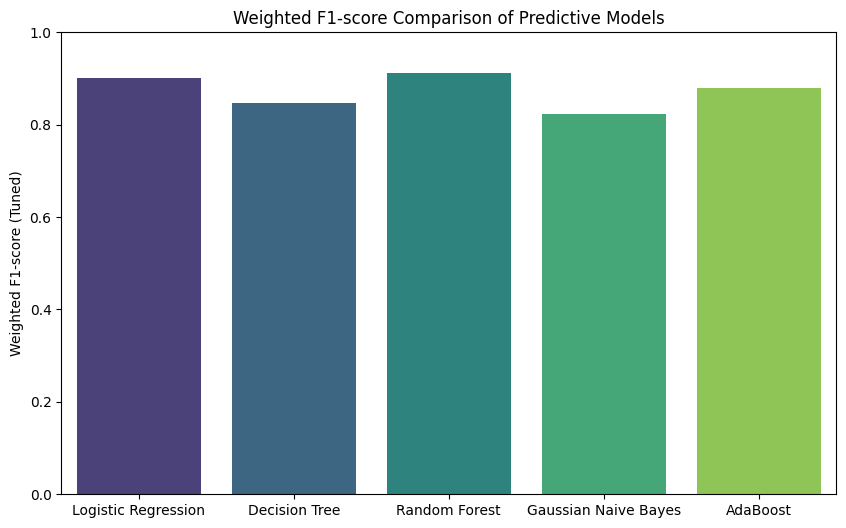

In [ ]:
import matplotlib.pyplot as plt
models = ['Logistic Regression', 'Decision Tree', 'Random Forest', 'Gaussian Naive Bayes', 'AdaBoost']
f1_scores_tuned = [f1_weight_log_tuned, f1_weight_tree_random, f1_weight_forest_reg_random, f1_weight_nb, f1_weight_ada_random]

plt.figure(figsize=(10, 6))
sns.barplot(x=models, y=f1_scores_tuned, palette='viridis')
plt.ylabel('Weighted F1-score (Tuned)')
plt.title('Weighted F1-score Comparison of Predictive Models')
plt.ylim(0, 1)  # Assuming F1-scores are between 0 and 1
plt.show()

In [ ]:
models = [
    'Logistic Regression',
    'Decision Tree',
    'Random Forest',
    'Naive Bayes',
    'AdaBoost'
]

f1_scores = [
    f1_weight_log_tuned,
    f1_weight_tree_random,
    f1_weight_forest_reg_random,
    f1_weight_nb,
    f1_weight_ada_random
]

plt.figure(figsize=(18, 8))
sns.barplot(x=models, y=f1_scores, palette='viridis')
plt.ylabel('Weighted F1 Score')
plt.title('Comparison of Model Performance (Weighted F1 Score)')
plt.ylim(0, 1)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

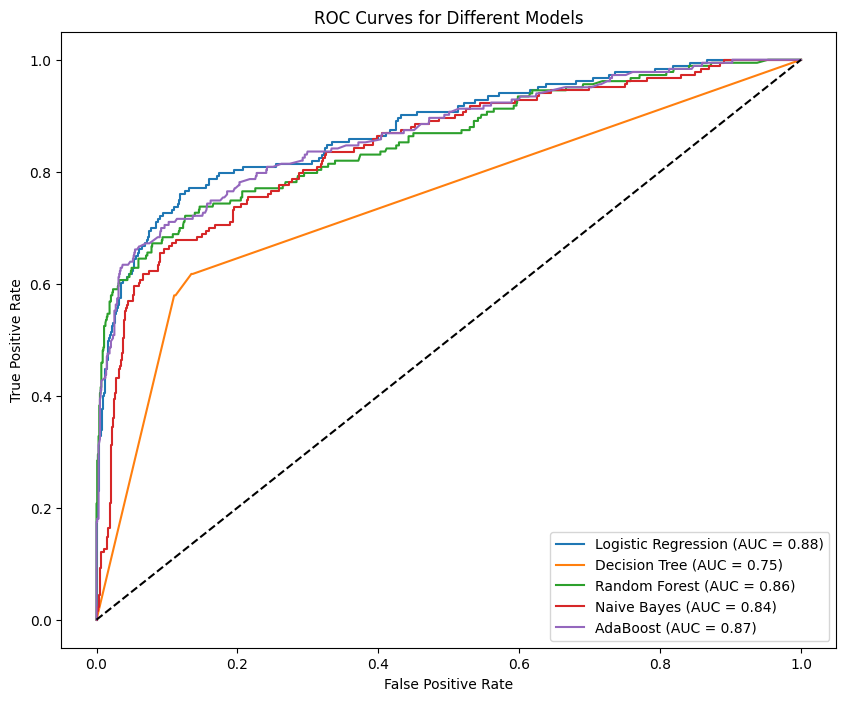

In [ ]:
# prompt: create roc curve

import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# Get predicted probabilities for the positive class (assuming 'Dead' is the positive class)
# You'll need to adjust this based on your 'Status' column values if 'Dead' is not the positive class.
# Check the unique values in y_test and the order returned by best_log_random.classes_
try:
  y_prob_log = best_log_random.predict_proba(x_test)[:, best_log_random.classes_.tolist().index('Dead')]
  fpr_log, tpr_log, thresholds_log = roc_curve(y_test, y_prob_log, pos_label = 'Dead')
  auc_log = roc_auc_score(y_test, y_prob_log)

  y_prob_tree = best_tree_random.predict_proba(x_test)[:, best_tree_random.classes_.tolist().index('Dead')]
  fpr_tree, tpr_tree, thresholds_tree = roc_curve(y_test, y_prob_tree, pos_label='Dead')
  auc_tree = roc_auc_score(y_test, y_prob_tree)

  y_prob_forest = best_random_model.predict_proba(x_test)[:, best_random_model.classes_.tolist().index('Dead')]
  fpr_forest, tpr_forest, thresholds_forest = roc_curve(y_test, y_prob_forest, pos_label='Dead')
  auc_forest = roc_auc_score(y_test, y_prob_forest)

  # For Naive Bayes, ensure the class order is correct
  y_prob_nb = best_nb_model.predict_proba(x_test)[:, best_nb_model.classes_.tolist().index('Dead')]
  fpr_nb, tpr_nb, thresholds_nb = roc_curve(y_test, y_prob_nb, pos_label='Dead')
  auc_nb = roc_auc_score(y_test, y_prob_nb)

  y_prob_ada = best_ada_random.predict_proba(x_test)[:, best_ada_random.classes_.tolist().index('Dead')]
  fpr_ada, tpr_ada, thresholds_ada = roc_curve(y_test, y_prob_ada, pos_label='Dead')
  auc_ada = roc_auc_score(y_test, y_prob_ada)

  plt.figure(figsize=(10, 8))
  plt.plot(fpr_log, tpr_log, label=f'Logistic Regression (AUC = {auc_log:.2f})')
  plt.plot(fpr_tree, tpr_tree, label=f'Decision Tree (AUC = {auc_tree:.2f})')
  plt.plot(fpr_forest, tpr_forest, label=f'Random Forest (AUC = {auc_forest:.2f})')
  plt.plot(fpr_nb, tpr_nb, label=f'Naive Bayes (AUC = {auc_nb:.2f})')
  plt.plot(fpr_ada, tpr_ada, label=f'AdaBoost (AUC = {auc_ada:.2f})')

  plt.plot([0, 1], [0, 1], 'k--')
  plt.xlabel('False Positive Rate')
  plt.ylabel('True Positive Rate')
  plt.title('ROC Curves for Different Models')
  plt.legend()
  plt.show()

except ValueError as e:
  print(f"Could not generate ROC curves. Check if 'Dead' is present in the target variable and the model's classes. Error: {e}")


 99%|===================| 2393/2416 [00:39<00:00]       

<Figure size 640x480 with 0 Axes>

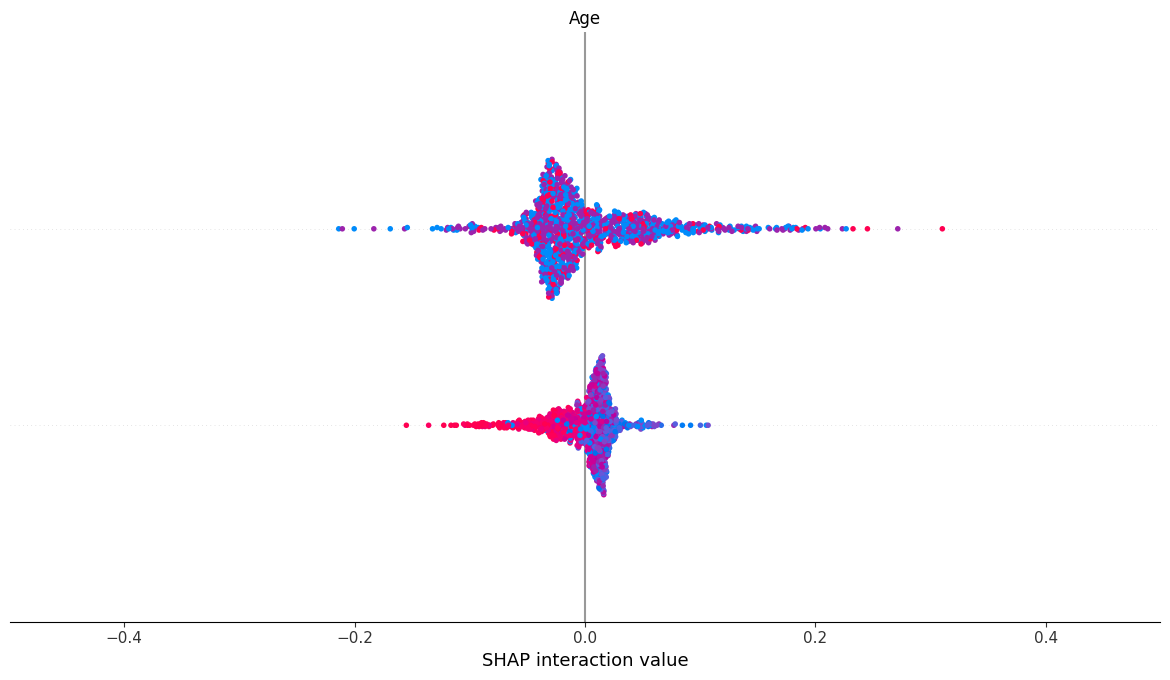

TypeError: In v0.20, force plot now requires the base value as the first parameter! Try shap.plots.force(explainer.expected_value, shap_values) or for multi-output models try shap.plots.force(explainer.expected_value[0], shap_values[..., 0]).

In [ ]:
import shap
import matplotlib.pyplot as plt

# Asumsikan model terbaik sudah dilatih:
# best_random_model = model Random Forest kamu
# x_train / x_test: data yang digunakan

explainer = shap.Explainer(best_random_model, x_train)
shap_values = explainer(x_test)

# Summary plot (fitur penting secara keseluruhan)
shap.summary_plot(shap_values, x_test)

# Force plot (1 pasien)
shap.plots.force(explainer.expected_value, shap_values[0])  # indeks pasien ke-0, Fixed: added explainer.expected_value